# Libraries

In [20]:
# Standard
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data Science
from scipy import stats
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from scipy.stats import shapiro, levene
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# Dataset

In [2]:
df = sns.load_dataset("penguins")

# Data Cleaning

Removed data with no sex 

In [3]:
print("Shape before cleaning", df.shape)
df = df[~df["sex"].isna()]
print("Shape after cleaning (new dataset)", df.shape)

Shape before cleaning (344, 7)
Shape after cleaning (new dataset) (333, 7)


# Descriptive statistics

count         mean         std     min      25%     50%  \
species   sex                                                               
Adelie    Female   73.0  3368.835616  269.380102  2850.0  3175.00  3400.0   
          Male     73.0  4043.493151  346.811553  3325.0  3800.00  4000.0   
Chinstrap Female   34.0  3527.205882  285.333912  2700.0  3362.50  3550.0   
          Male     34.0  3938.970588  362.137550  3250.0  3731.25  3950.0   
Gentoo    Female   58.0  4679.741379  281.578294  3950.0  4462.50  4700.0   
          Male     61.0  5484.836066  313.158596  4750.0  5300.00  5500.0   

                      75%     max  
species   sex                      
Adelie    Female  3550.00  3900.0  
          Male    4300.00  4775.0  
Chinstrap Female  3693.75  4150.0  
          Male    4100.00  4800.0  
Gentoo    Female  4875.00  5200.0  
          Male    5700.00  6300.0

<Axes: xlabel='species', ylabel='body_mass_g'>

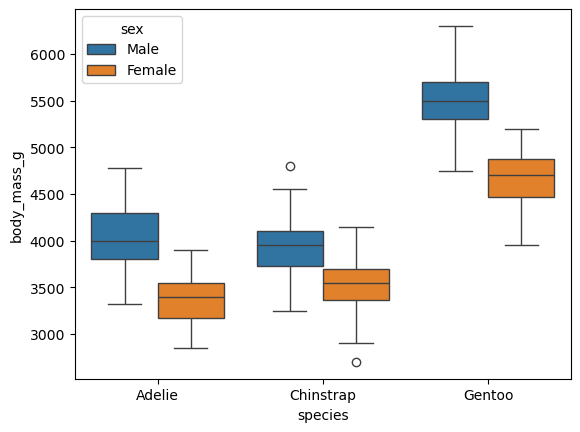

In [4]:
display(df.groupby(["species", "sex"])["body_mass_g"].describe())
sns.boxplot(x='species', y='body_mass_g', hue='sex', data=df)

# Two-way ANOVA

## Introduction

In the one-way ANOVA the dependent variable was weight, and the independent variable was the species.\
In the two-way ANOVA, another independent variable (sex) is added to the model, which becomes:

$weight = species + sex + species:sex$

the latter representing the interaction between species and sex

In this case there will be 3 questions:
* Main effect of species = Does the weight differ between species, regardless of the sex?
* Main effect of sex = Does the weight differ between sexes, regardless of the species?
* Species-sex interaction = Does the weight difference between males and females vary between species?

## ANOVA

In [5]:
df_two_way = df[
    ["species", "sex", "body_mass_g"]
].dropna()

It is important to check if all the combinations are represented

In [6]:
pd.crosstab(
    df_two_way["species"],
    df_two_way["sex"]
)

sex,Female,Male
species,,
Adelie,73,73
Chinstrap,34,34
Gentoo,58,61


Initially, Type II.
* Type I (Sequential Sum of Squares).
    * Evaluates factors in the order they are added to the model
    * In this case,
        1. species, 
        2. then sex (considering what was already explained by species)
        3. then interaction (considering what was already explained by previous steps)
* Type II (Hierarchical Sum of Squares)
    * Evaluates main effects considering the other main effect, without accounting for the interaction
    * In this case,
        1. species evaluated by sex, 
        2. sex evaluated by species
        3. interaction evaluated after considering both main effects
* Type III (Partial Sum of Squares)
    * Evaluates all effects considering all the other effects (also the interaction)


Type II is important when the focus is on the main effects

In [7]:
model_two_way = ols(
    "body_mass_g ~ C(species) * C(sex)",
    data=df_two_way
).fit()

In [8]:
anova_two_way = anova_lm(
    model_two_way,
    typ=2
)

print(anova_two_way)

                         sum_sq     df           F         PR(>F)
C(species)         1.434016e+08    2.0  749.015666  8.144406e-123
C(sex)             3.709026e+07    1.0  387.459976   1.902273e-57
C(species):C(sex)  1.676557e+06    2.0    8.756997   1.973489e-04
Residual           3.130263e+07  327.0         NaN            NaN


This means:
* there is a significant main effect of species 
* there is a significant main effect of sex
* there is a significant effect of the interaction

## Assumptions

Normality of residuals, homogeneity of variances, outliers

In [9]:
# Normality of residuals
shapiro_result = shapiro(model_two_way.resid)

print("Shapiro-Wilk:", shapiro_result)

# Homogeneity of variance
cell_groups = [
    group["body_mass_g"].values
    for _, group in df_two_way.groupby(["species", "sex"])
]

levene_result = levene(*cell_groups)

print("Levene:", levene_result)

Shapiro-Wilk: ShapiroResult(statistic=np.float64(0.9977609787241558), pvalue=np.float64(0.936685240182822))
Levene: LeveneResult(statistic=np.float64(1.3908258638296644), pvalue=np.float64(0.22721658048296114))


Both tests are successful, so the residuals of the model are normally distributed and variances are homogeneous 

## Interaction plot

In [10]:
means_table = df_two_way.pivot_table(
    values="body_mass_g",
    index="species",
    columns="sex",
    aggfunc="mean"
)

print(means_table)

sex             Female         Male
species                            
Adelie     3368.835616  4043.493151
Chinstrap  3527.205882  3938.970588
Gentoo     4679.741379  5484.836066


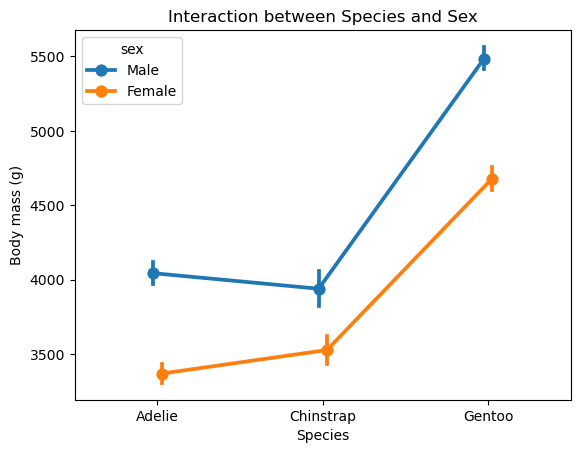

In [11]:
sns.pointplot(
    data=df_two_way,
    x="species",
    y="body_mass_g",
    hue="sex",
    errorbar=("ci", 95),
    dodge=True
)

plt.title("Interaction between Species and Sex")
plt.ylabel("Body mass (g)")
plt.xlabel("Species")
plt.show()

# Effect size

This time it is a partial eta-squared:
* includes only Sum of Squares of the measured effect and its residual error
* excludes all other factors

In [12]:
effects = ["C(species)", "C(sex)", "C(species):C(sex)"]

for effect in effects:
    ss_effect = anova_two_way.loc[effect, "sum_sq"]
    ss_error = anova_two_way.loc["Residual", "sum_sq"]

    eta_p2 = ss_effect / (ss_effect + ss_error)

    print(f"{effect}: {eta_p2:.4f}")

C(species): 0.8208
C(sex): 0.5423
C(species):C(sex): 0.0508


Very high effects for species and sex, while moderate effect for the interaction

# Simple Effects Analysis and Post-Hoc Comparisons

We have a significant interaction between species and sex, even if moderate (effect size).\
But which interactions are significant?

The questions are:
* Does sex affect the weight within species? Males vs females for
    * Adelie
    * Chinstrap
    * Gentoo
* Does species affect the weight within sexes? Adelie vs Chinstrap vs Gentoo for
    * Males
    * Females

## Sex differences within species 

First question = males vs females, 3 times (one for each species).\
This t-test assumes equal variances (verified with the Levene test).\
In the case it is not verified, the Welch t-test can be employed

### Significance

In [13]:
species_list = ["Adelie", "Chinstrap", "Gentoo"]

results = []

for species in species_list:

    male = df_two_way[
        (df_two_way["species"] == species) &
        (df_two_way["sex"] == "Male")
    ]["body_mass_g"]

    female = df_two_way[
        (df_two_way["species"] == species) &
        (df_two_way["sex"] == "Female")
    ]["body_mass_g"]

    test = ttest_ind(
        male,
        female,
        equal_var=True
    )

    results.append({
        "species": species,
        "mean_difference": male.mean() - female.mean(),
        "t_statistic": test.statistic,
        "p_value": test.pvalue
    })

Correction for multiple tests (Holm-correction). The family of comparisons is the 3 comparisons male vs female for the 3 species

In [14]:
p_values = [r["p_value"] for r in results]

reject, p_adjusted, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method="holm"
)

for i, result in enumerate(results):
    result["p_adjusted"] = p_adjusted[i]
    result["significant"] = reject[i]

results_df = pd.DataFrame(results)

results_df

,species,mean_difference,t_statistic,p_value,p_adjusted,significant
0,Adelie,674.657534,13.126286,2.220644e-26,4.441287e-26,True
1,Chinstrap,411.764706,5.207734,2.043956e-06,2.043956e-06,True
2,Gentoo,805.094686,14.721676,2.133688e-28,6.401063e-28,True


All differences are significant for all 3 species, but in a more pronounced way for Adelie and Gentoo

For comparison, I could have also applied a pairwise Tukey HSD

In [23]:
for species in ["Adelie", "Chinstrap", "Gentoo"]:

    subset = df_two_way[df_two_way["species"] == species]

    tukey = pairwise_tukeyhsd(
        endog=subset["body_mass_g"],
        groups=subset["sex"],
        alpha=0.05
    )

    print(f"\nTukey HSD - {species}")
    print(tukey)


Tukey HSD - Adelie
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj  lower    upper   reject
-----------------------------------------------------
Female   Male 674.6575   0.0 573.0666 776.2484   True
-----------------------------------------------------

Tukey HSD - Chinstrap
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj  lower    upper   reject
-----------------------------------------------------
Female   Male 411.7647   0.0 253.9005 569.6289   True
-----------------------------------------------------

Tukey HSD - Gentoo
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj  lower    upper   reject
-----------------------------------------------------
Female   Male 805.0947   0.0 696.7886 913.4008   True
-----------------------------------------------------


### Effect size

Hedge's g measures the effect size for small groups. It is a corrected version of Cohen's d that accounts for the distortion in small samples.\
Conventional thresholds are:
* g < 0.20 -> small effect
* g = 0.50 -> intermediate effect
* g = 0.80 -> big effect
* g = 1.20 -> very big effect

In [15]:
for result in results:

    species = result["species"]

    male = df_two_way[
        (df_two_way["species"] == species) &
        (df_two_way["sex"] == "Male")
    ]["body_mass_g"]

    female = df_two_way[
        (df_two_way["species"] == species) &
        (df_two_way["sex"] == "Female")
    ]["body_mass_g"]

    n1, n2 = len(male), len(female)

    pooled_sd = np.sqrt(
        ((n1 - 1) * male.var(ddof=1) +
         (n2 - 1) * female.var(ddof=1))
        / (n1 + n2 - 2)
    )

    d = (male.mean() - female.mean()) / pooled_sd

    J = 1 - 3 / (4 * (n1 + n2) - 9)

    result["hedges_g"] = J * d

In [16]:
results_df = pd.DataFrame(results)
results_df

,species,mean_difference,t_statistic,p_value,p_adjusted,significant,hedges_g
0,Adelie,674.657534,13.126286,2.220644e-26,4.441287e-26,True,2.161343
1,Chinstrap,411.764706,5.207734,2.043956e-06,2.043956e-06,True,1.248653
2,Gentoo,805.094686,14.721676,2.133688e-28,6.401063e-28,True,2.682582


g is not limited between 0 and 1, but varies from $- \infty$ to $+ \infty$.\
It is not a percentage of variance, and should not be mistaken with eta-squared.

The sex variations are more marked for Adelie and Gentoo, but are all large 

## Species differences between sexes

Second question = differences between species, 2 times (one for each sex).\
This t-test assumes equal variances (verified with the Levene test).

### Significance

In [17]:
sex_list = ["Male", "Female"]
species_list = ["Adelie", "Chinstrap", "Gentoo"]

results = []

for sex in sex_list:

    adelie = df_two_way[
        (df_two_way["species"] == "Adelie") &
        (df_two_way["sex"] == sex)
    ]["body_mass_g"]

    chinstrap = df_two_way[
        (df_two_way["species"] == "Chinstrap") &
        (df_two_way["sex"] == sex)
    ]["body_mass_g"]

    gentoo = df_two_way[
        (df_two_way["species"] == "Gentoo") &
        (df_two_way["sex"] == sex)
    ]["body_mass_g"]

    # Comparisons

    for species1, species2, group1, group2 in [
        ("Adelie", "Chinstrap", adelie, chinstrap),
        ("Adelie", "Gentoo", adelie, gentoo),
        ("Chinstrap", "Gentoo", chinstrap, gentoo)
    ]:

        test = ttest_ind(group1, group2, equal_var=True)

        results.append({
            "sex": sex,
            "comparison": f"{species1} vs {species2}",
            "mean_difference": group1.mean() - group2.mean(),
            "t_statistic": test.statistic,
            "p_value": test.pvalue
        })

results_df = pd.DataFrame(results)

results_df

,sex,comparison,mean_difference,t_statistic,p_value
0,Male,Adelie vs Chinstrap,104.522562,1.431352,1.552992e-01
1,Male,Adelie vs Gentoo,-1441.342915,-25.031353,5.752830e-52
2,Male,Chinstrap vs Gentoo,-1545.865477,-21.797355,2.554379e-38
3,Female,Adelie vs Chinstrap,-158.370266,-2.778751,6.466229e-03
4,Female,Adelie vs Gentoo,-1310.905763,-27.116674,3.963187e-55
5,Female,Chinstrap vs Gentoo,-1152.535497,-18.857628,5.120970e-33


Correction for multiple tests (Holm-correction). The family of comparisons is the 6 comparisons

In [18]:
p_values = [r["p_value"] for r in results]

reject, p_adjusted, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method="holm"
)

for i, result in enumerate(results):
    result["p_adjusted"] = p_adjusted[i]
    result["significant"] = reject[i]

results_df = pd.DataFrame(results)

results_df

,sex,comparison,mean_difference,t_statistic,p_value,p_adjusted,significant
0,Male,Adelie vs Chinstrap,104.522562,1.431352,1.552992e-01,1.552992e-01,False
1,Male,Adelie vs Gentoo,-1441.342915,-25.031353,5.752830e-52,2.876415e-51,True
2,Male,Chinstrap vs Gentoo,-1545.865477,-21.797355,2.554379e-38,1.021752e-37,True
3,Female,Adelie vs Chinstrap,-158.370266,-2.778751,6.466229e-03,1.293246e-02,True
4,Female,Adelie vs Gentoo,-1310.905763,-27.116674,3.963187e-55,2.377912e-54,True
5,Female,Chinstrap vs Gentoo,-1152.535497,-18.857628,5.120970e-33,1.536291e-32,True


Let's list the results:
* Gentoo is different from the other species, for both sexes
* Adelie and Chinstrap are instead significantly different for females, but not for males

For comparison, I could have also used a pairwise Tukey HSD

In [22]:
for sex in ["Male", "Female"]:

    subset = df_two_way[df_two_way["sex"] == sex]

    tukey = pairwise_tukeyhsd(
        endog=subset["body_mass_g"],
        groups=subset["species"],
        alpha=0.05
    )

    print(f"\nTukey HSD - {sex}")
    print(tukey)


Tukey HSD - Male
     Multiple Comparison of Means - Tukey HSD, FWER=0.05      
  group1    group2   meandiff p-adj   lower     upper   reject
--------------------------------------------------------------
   Adelie Chinstrap -104.5226 0.299 -270.5952     61.55  False
   Adelie    Gentoo 1441.3429   0.0 1302.5929 1580.0929   True
Chinstrap    Gentoo 1545.8655   0.0  1374.681   1717.05   True
--------------------------------------------------------------

Tukey HSD - Female
      Multiple Comparison of Means - Tukey HSD, FWER=0.05      
  group1    group2   meandiff p-adj    lower     upper   reject
---------------------------------------------------------------
   Adelie Chinstrap  158.3703 0.0179   22.3208  294.4197   True
   Adelie    Gentoo 1310.9058    0.0 1195.6491 1426.1624   True
Chinstrap    Gentoo 1152.5355    0.0 1011.0062 1294.0648   True
---------------------------------------------------------------


### Effect size

Hedge's g measures the effect size for small groups. It is a corrected version of Cohen's d that accounts for the distortion in small samples.\
Conventional thresholds are:
* g < 0.20 -> small effect
* g = 0.50 -> intermediate effect
* g = 0.80 -> big effect
* g = 1.20 -> very big effect

In [19]:
for result in results:

    sex = result["sex"]

    species1, species2 = result["comparison"].split(" vs ")

    group1 = df_two_way[
        (df_two_way["species"] == species1) &
        (df_two_way["sex"] == sex)
    ]["body_mass_g"]

    group2 = df_two_way[
        (df_two_way["species"] == species2) &
        (df_two_way["sex"] == sex)
    ]["body_mass_g"]

    n1, n2 = len(group1), len(group2)

    pooled_sd = np.sqrt(
        ((n1 - 1) * group1.var(ddof=1) +
         (n2 - 1) * group2.var(ddof=1))
        / (n1 + n2 - 2)
    )

    d = (group1.mean() - group2.mean()) / pooled_sd

    J = 1 - 3 / (4 * (n1 + n2) - 9)

    result["hedges_g"] = J * d

results_df = pd.DataFrame(results)

results_df

,sex,comparison,mean_difference,t_statistic,p_value,p_adjusted,significant,hedges_g
0,Male,Adelie vs Chinstrap,104.522562,1.431352,1.552992e-01,1.552992e-01,False,0.295064
1,Male,Adelie vs Gentoo,-1441.342915,-25.031353,5.752830e-52,2.876415e-51,True,-4.317487
2,Male,Chinstrap vs Gentoo,-1545.865477,-21.797355,2.554379e-38,1.021752e-37,True,-4.627380
3,Female,Adelie vs Chinstrap,-158.370266,-2.778751,6.466229e-03,1.293246e-02,True,-0.572822
4,Female,Adelie vs Gentoo,-1310.905763,-27.116674,3.963187e-55,2.377912e-54,True,-4.741976
5,Female,Chinstrap vs Gentoo,-1152.535497,-18.857628,5.120970e-33,1.536291e-32,True,-4.039086


If g > 0, the $1^{st}$ species has higher weight

* The species variations are more marked when Gentoo is involved (negative since Gentoo is the biggest species)
* Adelie males are bigger that Chinstrap males, with small-intermediate effect
* Adelie females are smaller that Chinstrap females, with intermediate-big effect 